## SUPPORT VECTOR MACHINE - RBF

In [1]:
# Load Libraries
import warnings
warnings.filterwarnings("ignore")
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from evaluation_script import evaluate_model

In [2]:
# Load Processed Data
data = joblib.load('../building/dataset_bundle.pkl')

X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']


### Finding the best parameters

In [3]:
# Declare parameters
param_grid = {
    'C': [1, 10, 100],
    'gamma': [0.01, 0.001],
    'probability': [True],
    'kernel': ['rbf'],
    
}


In [4]:
#create search space

SVM_grid = GridSearchCV(
    SVC(class_weight="balanced"),
    param_grid,
    cv=3,
    refit=True,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

print("hi")

hi


### Fit Model On Training

In [5]:
SVM_grid.fit(X_train , y_train)
best_model = SVM_grid.best_estimator_
best_model
print("done")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
done


### Evaluate On Test

In [6]:
evaluate_model(best_model, X_test, y_test)

{'Recall_Churn': 0.7085561497326203,
 'Precision_Churn': 0.44612794612794615,
 'F1_Churn': 0.5475206611570248,
 'ROC_AUC': 0.8292519288829252}

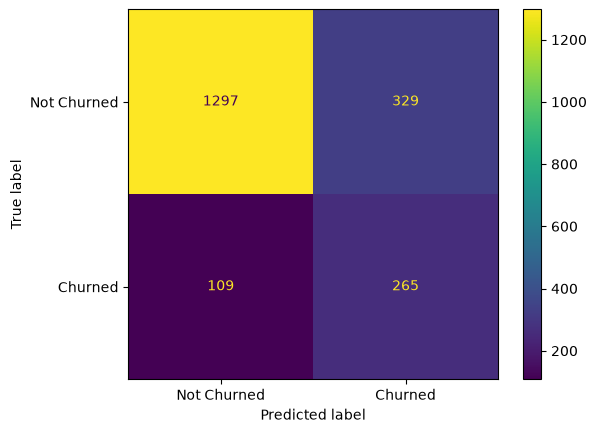

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = SVM_grid.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Churned", "Churned"]
)

plt.show()